In [1]:
# Cell 1: Install compatible NumPy and Brian2
!pip install -q "numpy<2.3" brian2

In [2]:
# Cell 2: Import Brian2 and plotting tools
import brian2
from brian2 import *
import matplotlib.pyplot as plt

print("Brian2 version:", brian2.__version__)
print("Ready to simulate neural circuits!")

Brian2 version: 2.10.1
Ready to simulate neural circuits!


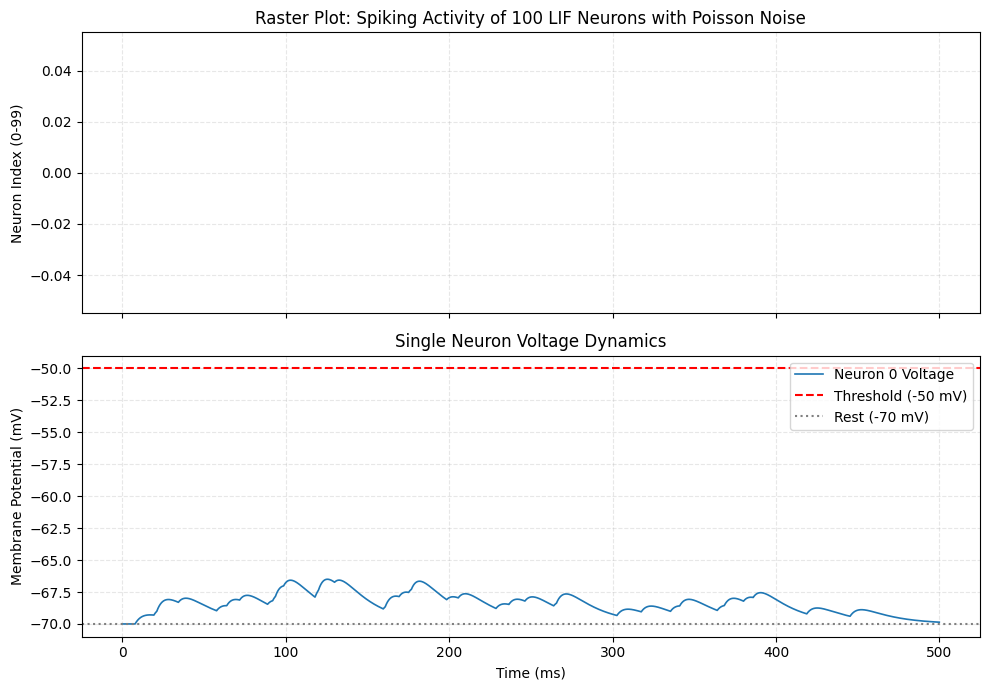

Total action potentials recorded across all 100 neurons: 0


In [3]:
# Cell 3: 100-Neuron LIF Network with Background Synaptic Noise

# 1. Reset simulation memory
start_scope()

# 2. Physiological Constants & Parameters
N = 100               # 100 LIF neurons
tau = 20 * ms         # Membrane leak time constant
v_rest = -70 * mV     # Resting membrane potential
v_thresh = -50 * mV   # Spike threshold
v_reset = -70 * mV    # Reset voltage after spike
refractory_t = 2 * ms # Refractory dead-time

# 3. Biological Differential Equations
lif_eqs = '''
dv/dt = (v_rest - v + g_syn) / tau : volt (unless refractory)
dg_syn/dt = -g_syn / (5*ms)          : volt
'''

# 4. Create the Neuron Population
neurons = NeuronGroup(
    N,
    lif_eqs,
    threshold='v > v_thresh',
    reset='v = v_reset',
    refractory=refractory_t,
    method='exact'
)
neurons.v = v_rest  # Start all cells at rest (-70 mV)

# 5. Background Synaptic Noise (Poisson Group)
# Simulates upstream background synaptic bombardment
poisson_noise = PoissonGroup(N, rates=80 * Hz)
noise_synapses = Synapses(poisson_noise, neurons, on_pre='g_syn += 4.5 * mV')
noise_synapses.connect(j='i')  # 1-to-1 input into each LIF neuron

# 6. Recorders / Monitors
spike_mon = SpikeMonitor(neurons)
volt_mon = StateMonitor(neurons, 'v', record=0)  # Record membrane potential of Neuron 0

# 7. Run Simulation
run(500 * ms)

# 8. Plot Raster and Membrane Potential
fig, (ax_raster, ax_volt) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Raster Plot
ax_raster.plot(spike_mon.t / ms, spike_mon.i, '.k', markersize=4)
ax_raster.set_ylabel('Neuron Index (0-99)')
ax_raster.set_title('Raster Plot: Spiking Activity of 100 LIF Neurons with Poisson Noise')
ax_raster.grid(True, linestyle='--', alpha=0.3)

# Voltage Dynamics of Neuron 0
ax_volt.plot(volt_mon.t / ms, volt_mon.v[0] / mV, color='#1f77b4', lw=1.2, label='Neuron 0 Voltage')
ax_volt.axhline(v_thresh / mV, color='red', linestyle='--', label=f'Threshold ({v_thresh/mV:.0f} mV)')
ax_volt.axhline(v_rest / mV, color='gray', linestyle=':', label=f'Rest ({v_rest/mV:.0f} mV)')
ax_volt.set_xlabel('Time (ms)')
ax_volt.set_ylabel('Membrane Potential (mV)')
ax_volt.set_title('Single Neuron Voltage Dynamics')
ax_volt.legend(loc='upper right')
ax_volt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Total action potentials recorded across all 100 neurons: {spike_mon.num_spikes}")

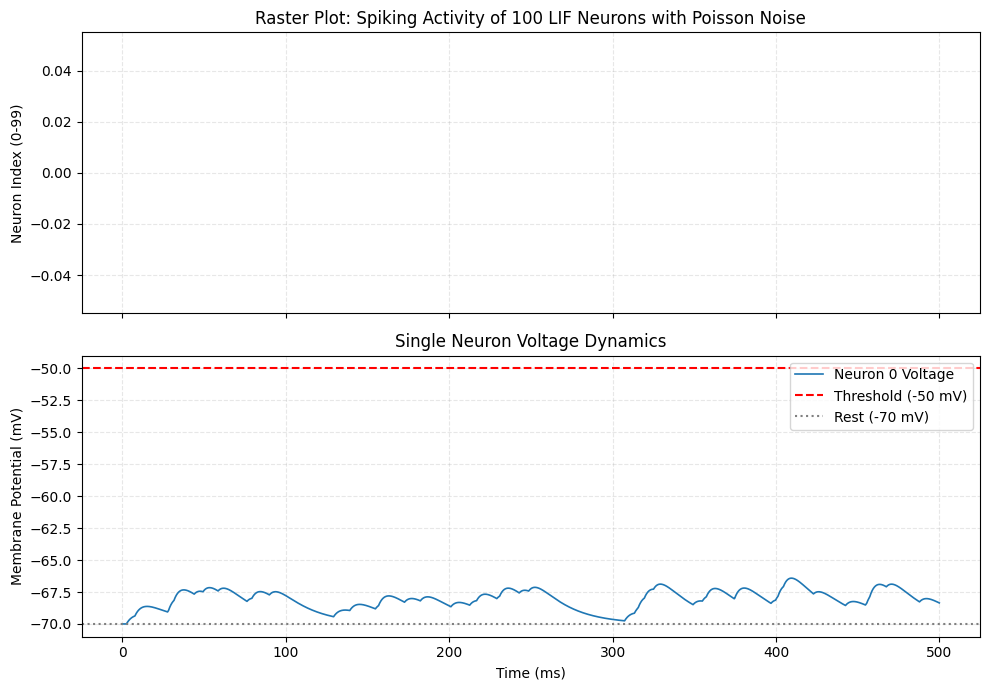

Total action potentials recorded across all 100 neurons: 0


In [4]:
# Cell 3: 100-Neuron LIF Network with Background Synaptic Noise

# 1. Reset simulation memory
start_scope()

# 2. Physiological Constants & Parameters
N = 100               # 100 LIF neurons
tau = 20 * ms         # Membrane leak time constant
v_rest = -70 * mV     # Resting membrane potential
v_thresh = -50 * mV   # Spike threshold
v_reset = -70 * mV    # Reset voltage after spike
refractory_t = 2 * ms # Refractory dead-time

# 3. Biological Differential Equations
lif_eqs = '''
dv/dt = (v_rest - v + g_syn) / tau : volt (unless refractory)
dg_syn/dt = -g_syn / (5*ms)          : volt
'''

# 4. Create the Neuron Population
neurons = NeuronGroup(
    N,
    lif_eqs,
    threshold='v > v_thresh',
    reset='v = v_reset',
    refractory=refractory_t,
    method='exact'
)
neurons.v = v_rest  # Start all cells at rest (-70 mV)

# 5. Background Synaptic Noise (Poisson Group)
# Simulates upstream background synaptic bombardment
poisson_noise = PoissonGroup(N, rates=80 * Hz)
noise_synapses = Synapses(poisson_noise, neurons, on_pre='g_syn += 4.5 * mV')
noise_synapses.connect(j='i')  # 1-to-1 input into each LIF neuron

# 6. Recorders / Monitors
spike_mon = SpikeMonitor(neurons)
volt_mon = StateMonitor(neurons, 'v', record=0)  # Record membrane potential of Neuron 0

# 7. Run Simulation
run(500 * ms)

# 8. Plot Raster and Membrane Potential
fig, (ax_raster, ax_volt) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Raster Plot
ax_raster.plot(spike_mon.t / ms, spike_mon.i, '.k', markersize=4)
ax_raster.set_ylabel('Neuron Index (0-99)')
ax_raster.set_title('Raster Plot: Spiking Activity of 100 LIF Neurons with Poisson Noise')
ax_raster.grid(True, linestyle='--', alpha=0.3)

# Voltage Dynamics of Neuron 0
ax_volt.plot(volt_mon.t / ms, volt_mon.v[0] / mV, color='#1f77b4', lw=1.2, label='Neuron 0 Voltage')
ax_volt.axhline(v_thresh / mV, color='red', linestyle='--', label=f'Threshold ({v_thresh/mV:.0f} mV)')
ax_volt.axhline(v_rest / mV, color='gray', linestyle=':', label=f'Rest ({v_rest/mV:.0f} mV)')
ax_volt.set_xlabel('Time (ms)')
ax_volt.set_ylabel('Membrane Potential (mV)')
ax_volt.set_title('Single Neuron Voltage Dynamics')
ax_volt.legend(loc='upper right')
ax_volt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Total action potentials recorded across all 100 neurons: {spike_mon.num_spikes}")

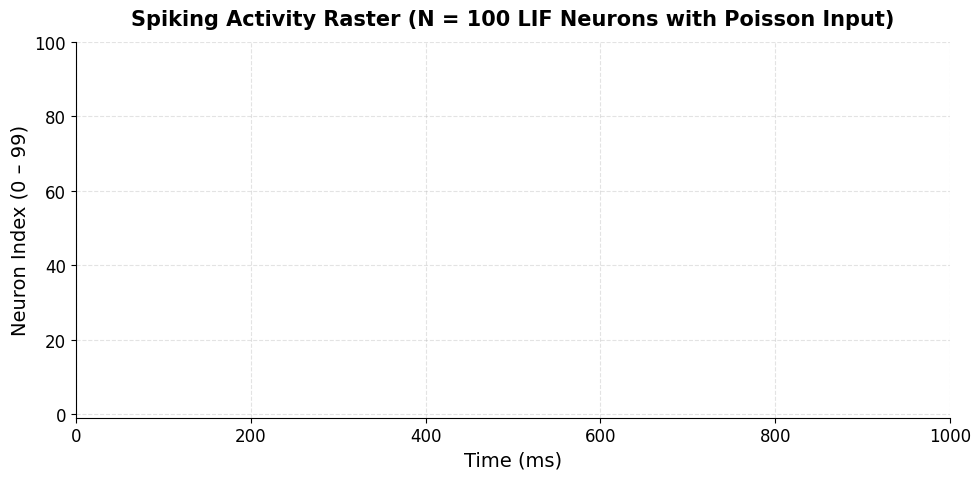

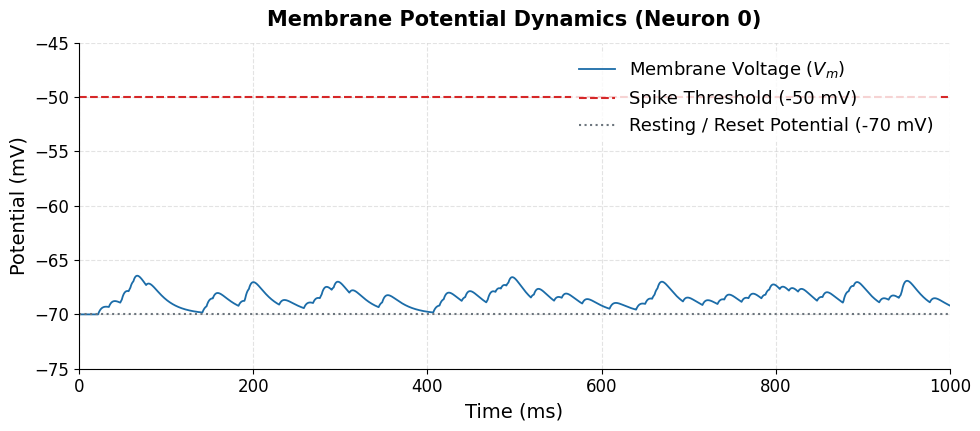

In [5]:
# -------------------------------------------------------------------------
# Step 1: Model Setup & 1000 ms Simulation
# -------------------------------------------------------------------------
import brian2
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

# Physiological parameters
N = 100               # Population size
tau = 20 * ms         # Membrane time constant
v_rest = -70 * mV     # Resting potential
v_thresh = -50 * mV   # Action potential threshold
v_reset = -70 * mV    # Reset potential
refractory_t = 2 * ms # Refractory dead-time

# Leaky Integrate-and-Fire dynamics
lif_eqs = '''
dv/dt = (v_rest - v + g_syn) / tau : volt (unless refractory)
dg_syn/dt = -g_syn / (5*ms)          : volt
'''

neurons = NeuronGroup(
    N,
    lif_eqs,
    threshold='v > v_thresh',
    reset='v = v_reset',
    refractory=refractory_t,
    method='exact'
)
neurons.v = v_rest

# Background Poisson synaptic input (80 Hz background bombardment)
poisson_noise = PoissonGroup(N, rates=80 * Hz)
noise_synapses = Synapses(poisson_noise, neurons, on_pre='g_syn += 4.5 * mV')
noise_synapses.connect(j='i')

# Recorders
spike_mon = SpikeMonitor(neurons)
volt_mon = StateMonitor(neurons, 'v', record=0)  # Record Neuron 0

# Run for 1000 milliseconds
simulation_time = 1000 * ms
run(simulation_time)

# -------------------------------------------------------------------------
# Step 2: Publication & Presentation Formatting (Aesthetics)
# -------------------------------------------------------------------------
plt.rcParams.update({
    'font.size': 13,
    'axes.labelsize': 14,
    'axes.titlesize': 15,
    'axes.spines.top': False,     # Remove top spine for clean presentation look
    'axes.spines.right': False,   # Remove right spine
    'xtick.labelsize': 12,
    'ytick.labelsize': 12
})

# -------------------------------------------------------------------------
# Graph 1: Raster Plot (Spike Times across all 100 Neurons)
# -------------------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(spike_mon.t / ms, spike_mon.i, '|', color='#1f2d3d', markersize=5, markeredgewidth=1.2)
ax1.set_xlim(0, 1000)
ax1.set_ylim(-1, N)
ax1.set_title('Spiking Activity Raster (N = 100 LIF Neurons with Poisson Input)', pad=12, fontweight='bold')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Neuron Index (0 – 99)')
ax1.grid(True, linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Graph 2: Single-Neuron Membrane Potential Trace (Neuron 0)
# -------------------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(10, 4.5))

ax2.plot(volt_mon.t / ms, volt_mon.v[0] / mV, color='#1b6ca8', lw=1.3, label='Membrane Voltage ($V_m$)')
ax2.axhline(v_thresh / mV, color='#d62728', linestyle='--', lw=1.5, label=f'Spike Threshold ({v_thresh/mV:.0f} mV)')
ax2.axhline(v_rest / mV, color='#6c757d', linestyle=':', lw=1.5, label=f'Resting / Reset Potential ({v_rest/mV:.0f} mV)')

ax2.set_xlim(0, 1000)
ax2.set_ylim(-75, -45)
ax2.set_title('Membrane Potential Dynamics (Neuron 0)', pad=12, fontweight='bold')
ax2.set_xlabel('Time (ms)')
ax2.set_ylabel('Potential (mV)')
ax2.legend(frameon=True, facecolor='white', edgecolor='none', loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()